# UBL news-only MLP —original model + walk-forward + multi-horizon

Sections: **A** data prep and original single-split model, **B** walk-forward validation, **C** multi-horizon forecasting.

News features: `n_articles, sent_mean, sent_extreme, has_news, recency, sent_decay` + 8 PCA components of the FinBERT embedding. The PCA is **fit on training rows only** (re-fit inside every walk-forward fold and every horizon), so no future information leaks in.

## A. Data loading and preparation

In [2]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, layers, callbacks
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error as MAE,
    mean_squared_error as MSE,
    r2_score
)

# ---- CONFIG (Kaggle) ----
NEWS_PATH  = "/kaggle/input/datasets/raheenz/ubl-news-price/ubl_news_clean.csv"
PRICE_PATH = "/kaggle/input/datasets/raheenz/ubl-news-price/UBL.csv"
FEAT_DIR   = "/kaggle/working"
START = "2021-09-30"
END   = "2026-06-30"
RERUN_FINBERT = False
HALF_LIFE = 3            # trading days, news recency decay
N_PCA     = 8            # FinBERT embedding components
os.makedirs(FEAT_DIR, exist_ok=True)
print("NEWS exists:", os.path.exists(NEWS_PATH), "| PRICE exists:", os.path.exists(PRICE_PATH))

NEWS exists: True | PRICE exists: True


### FinBERT scoring (cached, unchanged)

In [3]:
# ============ STEP 1: FinBERT on the news (cached) ============
CACHE_S, CACHE_E = f"{FEAT_DIR}/article_scored.csv", f"{FEAT_DIR}/article_emb.npy"

if os.path.exists(CACHE_S) and os.path.exists(CACHE_E) and not RERUN_FINBERT:
    arts = pd.read_csv(CACHE_S, parse_dates=["pub_date", "feature_date"]); E = np.load(CACHE_E)
    print(f"loaded cached FinBERT output: {len(arts)} articles")
else:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", device)

    arts = pd.read_csv(NEWS_PATH, parse_dates=["pub_date", "feature_date"])
    tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
    model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").to(device).eval()
    id2 = {int(k): v.lower() for k, v in model.config.id2label.items()}
    POS, NEG, NEU = [[k for k, v in id2.items() if v == name][0] for name in ("positive", "negative", "neutral")]

    # split long articles into 510-token chunks
    chunks = []
    for i, (t, x) in enumerate(zip(arts["title"], arts["text"])):
        ids = tok(f"{t}. {x}", add_special_tokens=False)["input_ids"]
        for s in range(0, max(len(ids), 1), 510):
            chunks.append((i, ids[s:s + 510]))
    print(f"{len(arts)} articles -> {len(chunks)} chunks")

    BATCH, probs, embs = 8, [], []
    with torch.no_grad():
        for b in range(0, len(chunks), BATCH):
            batch = [[tok.cls_token_id] + ids + [tok.sep_token_id] for _, ids in chunks[b:b + BATCH]]
            L = max(len(x) for x in batch)
            input_ids = torch.tensor([x + [tok.pad_token_id] * (L - len(x)) for x in batch]).to(device)
            out = model(input_ids=input_ids, attention_mask=(input_ids != tok.pad_token_id).long(), output_hidden_states=True)
            probs.append(torch.softmax(out.logits, -1).cpu().numpy())
            embs.append(out.hidden_states[-1][:, 0, :].cpu().numpy())
            if (b // BATCH) % 10 == 0: print(f"  {min(b + BATCH, len(chunks))}/{len(chunks)} chunks")
    probs, embs = np.vstack(probs), np.vstack(embs)

    # chunks -> articles
    rows = np.array([r for r, _ in chunks]); w = np.array([len(ids) for _, ids in chunks], float)
    P, E, W = np.zeros((len(arts), 3)), np.zeros((len(arts), 768)), np.zeros(len(arts))
    np.add.at(P, rows, probs * w[:, None]); np.add.at(E, rows, embs * w[:, None]); np.add.at(W, rows, w)
    P /= W[:, None]; E /= W[:, None]
    arts["p_pos"], arts["p_neg"], arts["p_neu"] = P[:, POS], P[:, NEG], P[:, NEU]
    arts["sentiment"] = arts["p_pos"] - arts["p_neg"]
    arts.to_csv(CACHE_S, index=False); np.save(CACHE_E, E)
    print("saved FinBERT output to", FEAT_DIR)

print(arts["sentiment"].describe().round(3))
print("\nMost positive:"); print(arts.nlargest(5, "sentiment")[["pub_date", "title"]].to_string(index=False))
print("\nMost negative:"); print(arts.nsmallest(5, "sentiment")[["pub_date", "title"]].to_string(index=False))

device: cuda


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (700 > 512). Running this sequence through the model will result in indexing errors


277 articles -> 475 chunks
  8/475 chunks
  88/475 chunks
  168/475 chunks
  248/475 chunks
  328/475 chunks
  408/475 chunks
saved FinBERT output to /kaggle/working
count    277.000
mean       0.229
std        0.568
min       -0.966
25%       -0.032
50%        0.256
75%        0.774
max        0.939
Name: sentiment, dtype: float64

Most positive:
  pub_date                                                                    title
2021-07-16      Analyst Briefing: PTCL plans CAPEX of Rs20bn to expand FTHH Network
2026-05-14                                JazzWorld delivers strong Q1 2026 results
2025-10-15 UBL profit soars past Rs. 100 billion, declares Rs. 21.50 total dividend
2026-01-19                JazzWorld, UBL seal Pakistan’s largest interest rate swap
2025-10-15                      UBL profit jumps 89% YoY to Rs35.36bn in Q3 of 2025

Most negative:
  pub_date                                         title
2026-04-14      PSX sees a sharp and broad-based decline
2026-03-28      

### Price data 


In [5]:
price_data = pd.read_csv(PRICE_PATH)
price_data.columns = [c.strip().upper() for c in price_data.columns]
price_data["DATE"] = pd.to_datetime(price_data["DATE"])

price_data_5yr = price_data[price_data["DATE"] >= pd.Timestamp("2021-01-01")].copy()
print("Missing values:", int(price_data_5yr.isnull().sum().sum()),
      "| exact duplicate rows:", int(price_data_5yr.duplicated().sum()))
price_data_5yr = price_data_5yr.drop_duplicates()

valid_price = (
    (price_data_5yr["OPEN"] > 0) & (price_data_5yr["HIGH"] > 0) &
    (price_data_5yr["LOW"] > 0) & (price_data_5yr["CLOSE"] > 0) &
    (price_data_5yr["VOLUME"] >= 0) &
    (price_data_5yr["HIGH"] >= price_data_5yr["OPEN"]) &
    (price_data_5yr["HIGH"] >= price_data_5yr["CLOSE"]) &
    (price_data_5yr["HIGH"] >= price_data_5yr["LOW"]) &
    (price_data_5yr["LOW"] <= price_data_5yr["OPEN"]) &
    (price_data_5yr["LOW"] <= price_data_5yr["CLOSE"])
)
print("Invalid price records removed:", int((~valid_price).sum()))
price_data_5yr = price_data_5yr[valid_price].drop_duplicates("DATE").sort_values("DATE").reset_index(drop=True)

price_aligned = price_data_5yr[(price_data_5yr["DATE"] >= START) & (price_data_5yr["DATE"] <= END)].reset_index(drop=True)
print("Price data after date alignment:", price_aligned.shape)

Missing values: 0 | exact duplicate rows: 0
Invalid price records removed: 0
Price data after date alignment: (1176, 7)


### Daily news features on the price calendar

In [7]:
# Drop articles dated before the price window; otherwise merge_asof(forward) piles them all onto the first trading day.
first_day = price_aligned["DATE"].min()
keep_a = (arts["feature_date"] >= first_day).values
print(f"dropped {int((~keep_a).sum())} articles dated before {first_day.date()}")
arts_w = arts[keep_a].reset_index(drop=True)
E_w = E[keep_a]
arts_w["row"] = np.arange(len(arts_w))

# each article -> first trading day on/after its feature_date (handles weekends and PSX holidays)
a = pd.merge_asof(arts_w.sort_values("feature_date"),
                  price_aligned[["DATE"]].rename(columns={"DATE": "trade_date"}),
                  left_on="feature_date", right_on="trade_date",
                  direction="forward").dropna(subset=["trade_date"]).reset_index(drop=True)
E_s = E_w[a["row"].values]

g = a.groupby("trade_date")
daily = pd.DataFrame({
    "n_articles":   g.size(),
    "sent_mean":    g["sentiment"].mean(),
    "sent_extreme": g["sentiment"].agg(lambda s: s.loc[s.abs().idxmax()]),
})
nd = price_aligned.set_index("DATE").join(daily)
nd["has_news"] = nd["n_articles"].notna().astype(int)
nd[["n_articles", "sent_mean", "sent_extreme"]] = nd[["n_articles", "sent_mean", "sent_extreme"]].fillna(0)

# daily FinBERT embedding (zero vector on no-news days)
D_all = np.zeros((len(nd), 768)); pos = {d: i for i, d in enumerate(nd.index)}
for d, idx in g.indices.items():
    D_all[pos[d]] = E_s[idx].mean(axis=0)

# recency / memory features (causal: only past news)
ds, last, m, memo, decay = [], -1, 0.0, [], 0.5 ** (1 / HALF_LIFE)
for i, (h, s) in enumerate(zip(nd["has_news"], nd["sent_mean"])):
    if h: last = i
    ds.append(i - last if last >= 0 else 60); m = m * decay + s; memo.append(m)
nd["recency"]    = 0.5 ** (np.minimum(ds, 60) / HALF_LIFE)
nd["sent_decay"] = memo

aligned_data = nd.reset_index()          # DATE back as a col
NEWS_COLS = ["n_articles", "sent_mean", "sent_extreme", "has_news", "recency", "sent_decay"]
EMB_COLS  = [f"pc{i}" for i in range(N_PCA)]
print("Aligned data:", aligned_data.shape, "| days with news:", int(nd.has_news.sum()), f"({nd.has_news.mean():.1%})")

dropped 17 articles dated before 2021-09-30
Aligned data: (1176, 13) | days with news: 166 (14.1%)


## Original model: news-only MLP, single 70/15/15 split

In [8]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# PCA of the FinBERT embedding must only see the rows the model trains on
def news_features(d, D_d, fit_idx):
    has = d["has_news"].values
    fi = np.asarray(fit_idx)
    fit_news = fi[has[fi] == 1]
    k = max(1, min(N_PCA, len(fit_news) - 1))
    pca = PCA(k, random_state=0).fit(D_d[fit_news])
    P = np.zeros((len(d), N_PCA))
    P[:, :k] = pca.transform(D_d) * has[:, None]          # zero on no-news days
    return pd.concat([d[NEWS_COLS].reset_index(drop=True),
                      pd.DataFrame(P, columns=EMB_COLS)], axis=1)

# ==========================================
# 1. NEXT-DAY TARGET (NEWS-ONLY INPUTS)
# ==========================================
df = aligned_data.sort_values("DATE").reset_index(drop=True).copy()
assert df["DATE"].is_monotonic_increasing
df["next_close"] = df["CLOSE"].shift(-1)                   # target = next trading day's close
df["tdate"]      = df["DATE"].shift(-1)                    # date being predicted
df["target_ret"] = np.log(df["next_close"] / df["CLOSE"])  # next-day log return
keep = df["next_close"].notna().values
df = df[keep].reset_index(drop=True)
D  = D_all[keep]

# ==========================================
# 2. INPUTS, TARGETS, CHRONOLOGICAL SPLIT
# ==========================================
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

X = news_features(df, D, np.arange(train_end))             # PCA fit on TRAIN rows only
feature_cols = list(X.columns)

y_price = df["next_close"]
y_return = df["target_ret"]
current_close = df["CLOSE"]          # only used to convert predicted return -> price, NOT an input
target_dates = pd.to_datetime(df["tdate"])

X_train, X_val, X_test = X.iloc[:train_end], X.iloc[train_end:val_end], X.iloc[val_end:]
y_price_train,  y_price_val,  y_price_test  = y_price.iloc[:train_end],  y_price.iloc[train_end:val_end],  y_price.iloc[val_end:]
y_return_train, y_return_val, y_return_test = y_return.iloc[:train_end], y_return.iloc[train_end:val_end], y_return.iloc[val_end:]
current_close_test = current_close.iloc[val_end:]

print("Features used:", len(feature_cols), feature_cols)
print("\nDataset Split:  Train", X_train.shape, "| Validation", X_val.shape, "| Test", X_test.shape)
print("Train:", df["DATE"].iloc[0].date(), "to", df["DATE"].iloc[train_end - 1].date())
print("Validation:", df["DATE"].iloc[train_end].date(), "to", df["DATE"].iloc[val_end - 1].date())
print("Test:", df["DATE"].iloc[val_end].date(), "to", df["DATE"].iloc[-1].date())

# ==========================================
# 3. FEATURE / TARGET SCALING (fit on train only)
# ==========================================
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled   = scaler_X.transform(X_val)
X_test_scaled  = scaler_X.transform(X_test)

scaler_y_price = StandardScaler()
y_price_train_scaled = scaler_y_price.fit_transform(y_price_train.values.reshape(-1, 1))
y_price_val_scaled   = scaler_y_price.transform(y_price_val.values.reshape(-1, 1))

scaler_y_return = StandardScaler()
y_return_train_scaled = scaler_y_return.fit_transform(y_return_train.values.reshape(-1, 1))
y_return_val_scaled   = scaler_y_return.transform(y_return_val.values.reshape(-1, 1))

Features used: 14 ['n_articles', 'sent_mean', 'sent_extreme', 'has_news', 'recency', 'sent_decay', 'pc0', 'pc1', 'pc2', 'pc3', 'pc4', 'pc5', 'pc6', 'pc7']

Dataset Split:  Train (822, 14) | Validation (176, 14) | Test (177, 14)
Train: 2021-09-30 to 2025-01-22
Validation: 2025-01-23 to 2025-10-09
Test: 2025-10-10 to 2026-06-29


I0000 00:00:1792844165.891607      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12804 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792844165.895233      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1792844170.199662     172 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



NEWS-ONLY MLP — ALL SPLITS

MODEL A — NEXT-DAY CLOSE (PRICE TARGET)
----------------------------------------------------------------------
Train: MAE 44.91 RMSE 57.85 MAPE 26.95% R2 0.355 DirAcc 48.4%
Validation: MAE 237.59 RMSE 249.28 MAPE 56.59% R2 -13.880 DirAcc 44.9%
Test: MAE 227.28 RMSE 233.67 MAPE 55.31% R2 -24.624 DirAcc 54.2%

MODEL B — NEXT-DAY LOG RETURN
----------------------------------------------------------------------
Train: MAE 1.95 RMSE 3.10 MAPE 1.13% R2 0.998 DirAcc 56.8%
Validation: MAE 7.75 RMSE 22.21 MAPE 2.05% R2 0.882 DirAcc 54.0%
Test: MAE 8.15 RMSE 11.38 MAPE 2.01% R2 0.939 DirAcc 52.5%

Test Predictions:
         DATE  Actual Close  MLP A (Price Target)  MLP B (Return Target)  \
0  2025-10-13        374.06            152.591354             376.788908   
1  2025-10-14        391.37            150.781479             374.775737   
2  2025-10-15        387.81            149.077072             392.135934   
3  2025-10-16        389.67            212.947052     

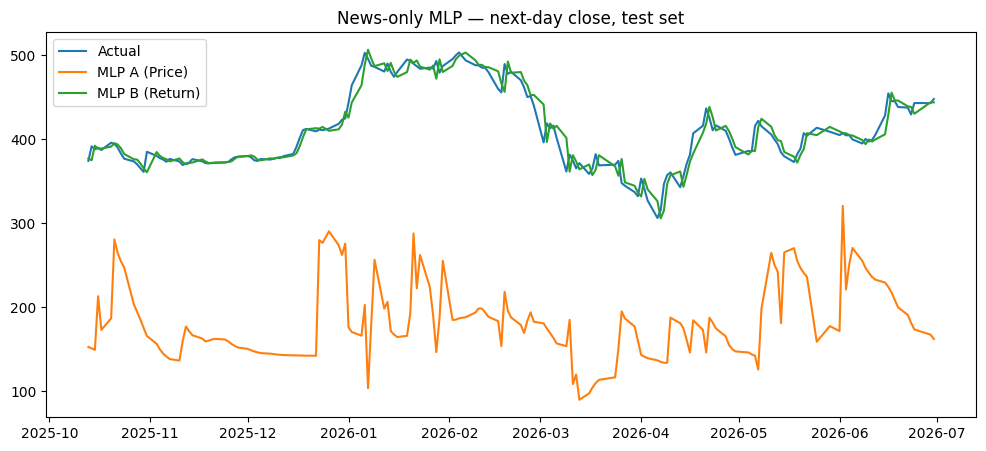

In [9]:
# ==========================================
# 4. METRICS 
# ==========================================
def report(name, actual, predicted, previous_close):
    mae = MAE(actual, predicted)
    rmse = np.sqrt(MSE(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    r2 = r2_score(actual, predicted)
    directional_accuracy = np.mean(
        np.sign(actual - previous_close) == np.sign(predicted - previous_close)
    ) * 100
    print(f"{name}: MAE {mae:.2f} RMSE {rmse:.2f} MAPE {mape:.2f}% R2 {r2:.3f} DirAcc {directional_accuracy:.1f}%")

# ==========================================
# 5. MLP MODEL
# ==========================================
def build_mlp():
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    model = Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

fit_kwargs = dict(epochs=200, batch_size=32, verbose=0,
                  callbacks=[callbacks.EarlyStopping(patience=20, restore_best_weights=True)])

# MODEL A — NEXT-DAY CLOSE
model_price = build_mlp()
model_price.fit(X_train_scaled, y_price_train_scaled,
                validation_data=(X_val_scaled, y_price_val_scaled), **fit_kwargs)

# MODEL B — NEXT-DAY LOG RETURN
model_return = build_mlp()
model_return.fit(X_train_scaled, y_return_train_scaled,
                 validation_data=(X_val_scaled, y_return_val_scaled), **fit_kwargs)

# ==========================================
# 6. PREDICTIONS — TRAIN / VALIDATION / TEST
# ==========================================
def inv(model, Xs, sc):
    return sc.inverse_transform(model.predict(Xs, verbose=0)).ravel()

pred_price_train = inv(model_price, X_train_scaled, scaler_y_price)
pred_price_val   = inv(model_price, X_val_scaled,scaler_y_price)
pred_price_test  = inv(model_price, X_test_scaled,  scaler_y_price)

pred_return_train = inv(model_return, X_train_scaled, scaler_y_return)
pred_return_val   = inv(model_return, X_val_scaled,   scaler_y_return)
pred_return_test  = inv(model_return, X_test_scaled,  scaler_y_return)

# predicted log return -> predicted next-day price
pred_return_price_train = current_close.iloc[:train_end].values * np.exp(pred_return_train)
pred_return_price_val   = current_close.iloc[train_end:val_end].values * np.exp(pred_return_val)
pred_return_price_test  = current_close_test.values * np.exp(pred_return_test)

# ==========================================
# 7. TRAIN / VALIDATION / TEST METRICS
# ==========================================
print("\nNEWS-ONLY MLP — ALL SPLITS")
print("=" * 70)
print("\nMODEL A — NEXT-DAY CLOSE (PRICE TARGET)"); print("-" * 70)
report("Train",      y_price_train.values, pred_price_train, current_close.iloc[:train_end].values)
report("Validation", y_price_val.values,   pred_price_val,   current_close.iloc[train_end:val_end].values)
report("Test",       y_price_test.values,  pred_price_test,  current_close_test.values)

print("\nMODEL B — NEXT-DAY LOG RETURN"); print("-" * 70)
report("Train",      y_price_train.values, pred_return_price_train, current_close.iloc[:train_end].values)
report("Validation", y_price_val.values,   pred_return_price_val,   current_close.iloc[train_end:val_end].values)
report("Test",       y_price_test.values,  pred_return_price_test,  current_close_test.values)

# ==========================================
# 8. SAVE TEST PREDICTIONS + PLOT
# ==========================================
results = pd.DataFrame({
    "DATE": target_dates.iloc[val_end:].values,
    "Actual Close": y_price_test.values,
    "MLP A (Price Target)": pred_price_test,
    "MLP B (Return Target)": pred_return_price_test,
    "has_news": df["has_news"].iloc[val_end:].values,
})
print("\nTest Predictions:"); print(results.head(20))
results.to_csv(f"{FEAT_DIR}/news_mlp_nextday_predictions.csv", index=False)

plt.figure(figsize=(12, 5))
plt.plot(results["DATE"], results["Actual Close"], label="Actual")
plt.plot(results["DATE"], results["MLP A (Price Target)"], label="MLP A (Price)")
plt.plot(results["DATE"], results["MLP B (Return Target)"], label="MLP B (Return)")
plt.title("News-only MLP — next-day close, test set")
plt.legend(); plt.show()

## B. Walk-forward validation

Same data, features and MLP as above. Only the **evaluation scheme** changes: the model is re-trained on past data and tested on the *next* block of days, then the window moves forward. The FinBERT PCA and the scalers are re-fit on each fold's training rows only.

In [10]:
# ==========================================
# WF-1. CONFIG
# ==========================================
WF_START        = val_end   # first fold's test block starts where the old single test set started (same test days -> comparable)
WF_STEP         = 21        # test block per fold ~ 1 trading month
WF_INNER_VAL    = 0.15      # last 15% of each training window is held out (chronologically) for early stopping
WF_ROLL_WINDOW  = val_end   # rolling mode: train on the most recent rows only (= size of fold-1 training window)

print("Total rows:", len(df))
print("First test row:", df['DATE'].iloc[WF_START].date(), "| Last:", df['DATE'].iloc[-1].date())
print("Number of folds:", int(np.ceil((len(df) - WF_START) / WF_STEP)))

Total rows: 1175
First test row: 2025-10-10 | Last: 2026-06-29
Number of folds: 9


In [27]:
# ==========================================
# WF-2. SAME MLP, FIT / PREDICT ONE FOLD
# ==========================================
def build_mlp_wf(n_features):
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    model = Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model


def fit_predict_fold(tr_idx, te_idx):
    # Train Model A (price) and Model B (log-return) on tr_idx, predict te_idx.
    # PCA, scalers and the early-stopping val set are all built from tr_idx only.
    n_tr = len(tr_idx)
    cut  = int(n_tr * (1 - WF_INNER_VAL))
    fit_idx, val_idx = tr_idx[:cut], tr_idx[cut:]

    Xn = news_features(df, D, fit_idx)          # PCA fit on fit_idx ONLY
    sx = StandardScaler()
    Xf = sx.fit_transform(Xn.iloc[fit_idx])
    Xv = sx.transform(Xn.iloc[val_idx])
    Xt = sx.transform(Xn.iloc[te_idx])

    out = {}
    for tag, y_series in [("A", y_price), ("B", y_return)]:
        sy = StandardScaler()
        yf = sy.fit_transform(y_series.iloc[fit_idx].values.reshape(-1, 1))
        yv = sy.transform(y_series.iloc[val_idx].values.reshape(-1, 1))

        m = build_mlp_wf(Xf.shape[1])
        m.fit(Xf, yf, validation_data=(Xv, yv),
              epochs=200, batch_size=32, verbose=0,
              callbacks=[callbacks.EarlyStopping(patience=20, restore_best_weights=True)])
        out[tag] = sy.inverse_transform(m.predict(Xt, verbose=0)).ravel()

    cur = current_close.iloc[te_idx].values
    return out["A"], cur * np.exp(out["B"]), cur

In [28]:
# ==========================================
# WF-3. WALK-FORWARD LOOP
# ==========================================
def walk_forward(mode="expanding"):
    rows = []
    fold = 0
    for start in range(WF_START, len(df), WF_STEP):
        end    = min(start + WF_STEP, len(df))
        tr_lo  = 0 if mode == "expanding" else max(0, start - WF_ROLL_WINDOW)
        tr_idx = np.arange(tr_lo, start)       # strictly BEFORE the test block
        te_idx = np.arange(start, end)

        pA, pB, cur = fit_predict_fold(tr_idx, te_idx)

        fold += 1
        rows.append(pd.DataFrame({
            "fold":        fold,
            "DATE":        target_dates.iloc[te_idx].values,
            "prev_close":  cur,
            "actual":      y_price.iloc[te_idx].values,
            "pred_A":      pA,
            "pred_B":      pB,
            "train_size":  len(tr_idx),
            "train_start": df["DATE"].iloc[tr_lo],
            "train_end":   df["DATE"].iloc[start - 1],
        }))
        print(f"[{mode}] fold {fold:>2} | train {len(tr_idx):>4} rows "
              f"({df['DATE'].iloc[tr_lo].date()} -> {df['DATE'].iloc[start-1].date()}) "
              f"| test {len(te_idx):>2} rows ({df['DATE'].iloc[start].date()} -> {df['DATE'].iloc[end-1].date()})")
    return pd.concat(rows, ignore_index=True)

wf_expanding = walk_forward("expanding")
wf_rolling   = walk_forward("rolling")

[expanding] fold  1 | train  998 rows (2021-09-30 -> 2025-10-09) | test 21 rows (2025-10-10 -> 2025-11-07)
[expanding] fold  2 | train 1019 rows (2021-09-30 -> 2025-11-07) | test 21 rows (2025-11-10 -> 2025-12-08)
[expanding] fold  3 | train 1040 rows (2021-09-30 -> 2025-12-08) | test 21 rows (2025-12-09 -> 2026-01-07)
[expanding] fold  4 | train 1061 rows (2021-09-30 -> 2026-01-07) | test 21 rows (2026-01-08 -> 2026-02-06)
[expanding] fold  5 | train 1082 rows (2021-09-30 -> 2026-02-06) | test 21 rows (2026-02-09 -> 2026-03-09)
[expanding] fold  6 | train 1103 rows (2021-09-30 -> 2026-03-09) | test 21 rows (2026-03-10 -> 2026-04-09)
[expanding] fold  7 | train 1124 rows (2021-09-30 -> 2026-04-09) | test 21 rows (2026-04-10 -> 2026-05-11)
[expanding] fold  8 | train 1145 rows (2021-09-30 -> 2026-05-11) | test 21 rows (2026-05-12 -> 2026-06-12)
[expanding] fold  9 | train 1166 rows (2021-09-30 -> 2026-06-12) | test  9 rows (2026-06-15 -> 2026-06-29)
[rolling] fold  1 | train  998 rows (

In [29]:
# ==========================================
# WF-4. METRICS (same definitions as report(), plus a naive baseline)
# ==========================================
def metrics(actual, pred, prev):
    actual, pred, prev = map(np.asarray, (actual, pred, prev))
    mae  = MAE(actual, pred)
    rmse = np.sqrt(MSE(actual, pred))
    mape = np.mean(np.abs((actual - pred) / actual)) * 100
    r2   = r2_score(actual, pred)
    pd_  = np.sign(pred - prev)
    dacc = np.mean(np.sign(actual - prev) == pd_) * 100 if np.any(pd_ != 0) else np.nan
    return dict(MAE=mae, RMSE=rmse, MAPE=mape, R2=r2, DirAcc=dacc)

def summarize(wf, label):
    rows = {
        f"{label} | Model A (price)":   metrics(wf.actual, wf.pred_A, wf.prev_close),
        f"{label} | Model B (return)":  metrics(wf.actual, wf.pred_B, wf.prev_close),
        f"{label} | Naive (yesterday)": metrics(wf.actual, wf.prev_close, wf.prev_close),
    }
    return pd.DataFrame(rows).T

# single-split result on the SAME test rows
single = pd.DataFrame({
    "Single split | Model A (price)":  metrics(y_price_test.values, pred_price_test, current_close_test.values),
    "Single split | Model B (return)": metrics(y_price_test.values, pred_return_price_test, current_close_test.values),
}).T

summary = pd.concat([single, summarize(wf_expanding, "WF expanding"), summarize(wf_rolling, "WF rolling")])

up_rate = np.mean(wf_expanding.actual > wf_expanding.prev_close) * 100
print(f"Test rows: {len(wf_expanding)} | Days the price actually went UP: {up_rate:.1f}% (a 'always up' guess scores this)\n")
print(summary.round(3).to_string())

Test rows: 177 | Days the price actually went UP: 45.8% (a 'always up' guess scores this)

                                      MAE     RMSE    MAPE      R2  DirAcc
Single split | Model A (price)    227.282  233.669  55.307 -24.624  54.237
Single split | Model B (return)     8.154   11.381   2.010   0.939  52.542
WF expanding | Model A (price)    210.847  217.855  51.512 -21.273  54.237
WF expanding | Model B (return)     8.147   11.399   2.012   0.939  49.153
WF expanding | Naive (yesterday)    7.859   11.103   1.944   0.942     NaN
WF rolling | Model A (price)      204.015  212.880  49.853 -20.267  54.237
WF rolling | Model B (return)       8.044   11.260   1.983   0.941  47.458
WF rolling | Naive (yesterday)      7.859   11.103   1.944   0.942     NaN


In [30]:
# ==========================================
# WF-5. PER-FOLD STABILITY
# ==========================================
def per_fold(wf):
    out = []
    for f, g_ in wf.groupby("fold"):
        a_ = metrics(g_.actual, g_.pred_A, g_.prev_close)
        b_ = metrics(g_.actual, g_.pred_B, g_.prev_close)
        n_ = metrics(g_.actual, g_.prev_close, g_.prev_close)
        out.append(dict(
            fold=f, test_from=pd.to_datetime(g_.DATE.iloc[0]).date(), n=len(g_),
            A_MAE=a_["MAE"], A_MAPE=a_["MAPE"], A_Dir=a_["DirAcc"],
            B_MAE=b_["MAE"], B_MAPE=b_["MAPE"], B_Dir=b_["DirAcc"],
            Naive_MAE=n_["MAE"]
        ))
    return pd.DataFrame(out)

fold_exp = per_fold(wf_expanding)
fold_rol = per_fold(wf_rolling)

print("EXPANDING WINDOW — per fold"); print(fold_exp.round(2).to_string(index=False))
print("\nROLLING WINDOW — per fold");   print(fold_rol.round(2).to_string(index=False))
print("\nMean ± std across folds (expanding):")
print(fold_exp[["A_MAE","B_MAE","Naive_MAE","A_Dir","B_Dir"]].agg(["mean","std"]).round(2).to_string())

EXPANDING WINDOW — per fold
 fold  test_from  n  A_MAE  A_MAPE  A_Dir  B_MAE  B_MAPE  B_Dir  Naive_MAE
    1 2025-10-13 21 190.46   50.19  76.19   5.52    1.45  42.86       5.37
    2 2025-11-11 21 202.80   54.13  42.86   1.74    0.46  66.67       1.72
    3 2025-12-10 21 218.03   51.44  23.81   6.94    1.55  66.67       7.09
    4 2026-01-09 21 263.41   53.96  57.14   6.98    1.43  47.62       6.12
    5 2026-02-10 21 220.38   49.29  71.43  13.86    3.28  33.33      13.00
    6 2026-03-11 21 230.25   64.73  52.38  11.80    3.40  47.62      11.52
    7 2026-04-13 21 184.25   46.15  52.38  11.39    2.87  52.38      11.56
    8 2026-05-13 21 161.79   40.38  52.38   6.98    1.74  42.86       6.51
    9 2026-06-16  9 246.77   55.76  66.67   8.09    1.82  33.33       7.79

ROLLING WINDOW — per fold
 fold  test_from  n  A_MAE  A_MAPE  A_Dir  B_MAE  B_MAPE  B_Dir  Naive_MAE
    1 2025-10-13 21 198.31   52.23  76.19   5.48    1.43  52.38       5.37
    2 2025-11-11 21 195.26   52.14  42.86   1

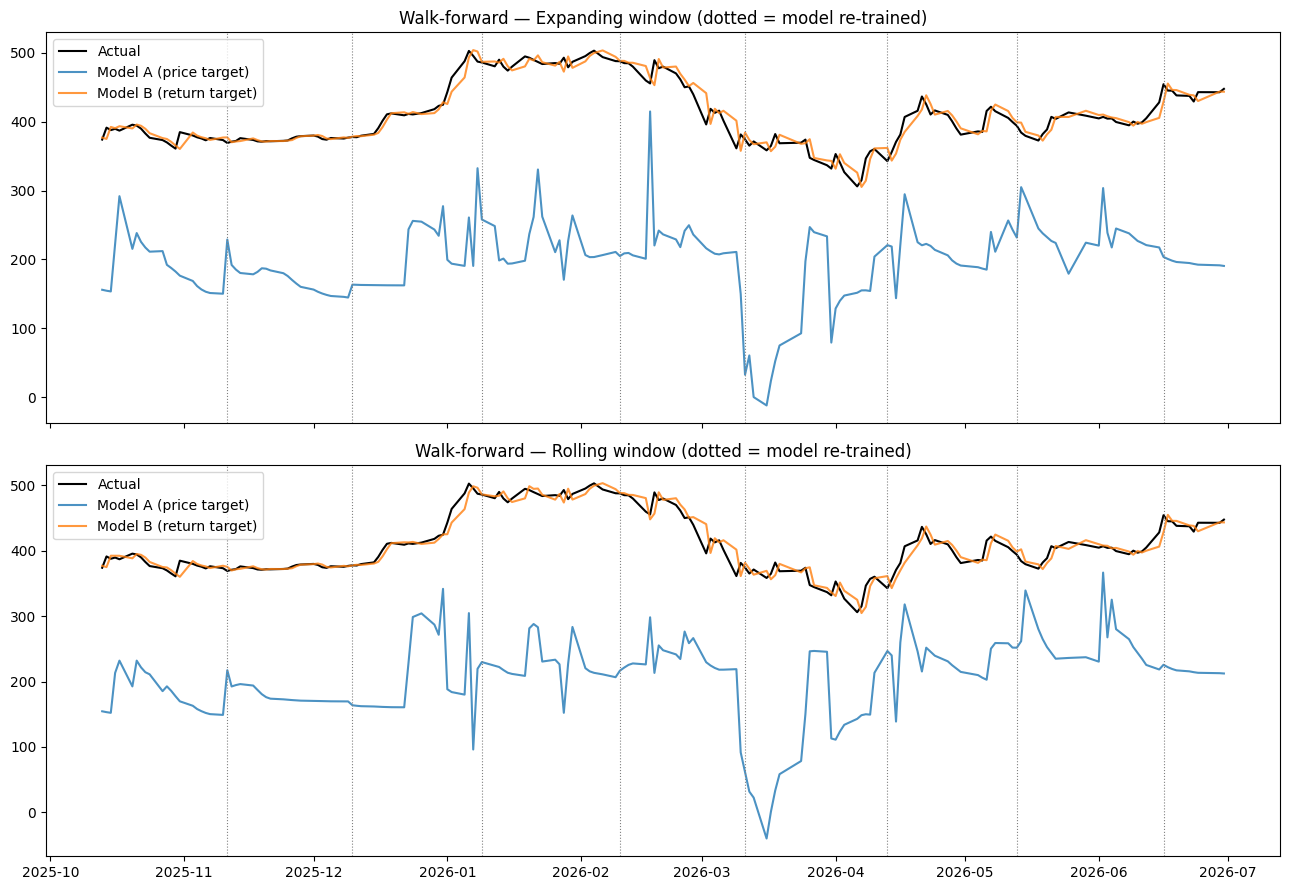

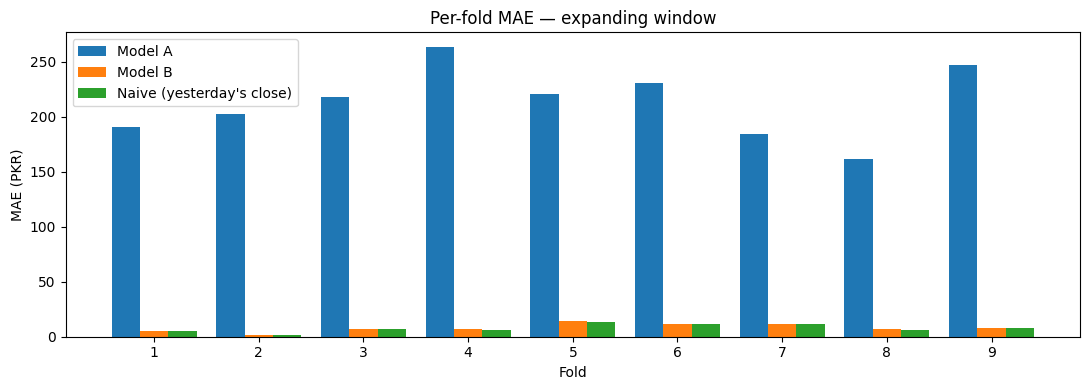

In [31]:
# ==========================================
# WF-6. PLOTS + SAVE
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for ax, wf, title in [(axes[0], wf_expanding, "Expanding window"),
                      (axes[1], wf_rolling,   "Rolling window")]:
    d_ = pd.to_datetime(wf["DATE"])
    ax.plot(d_, wf.actual, label="Actual", color="black", lw=1.5)
    ax.plot(d_, wf.pred_A, label="Model A (price target)", alpha=.8)
    ax.plot(d_, wf.pred_B, label="Model B (return target)", alpha=.8)
    for s in wf.groupby("fold").DATE.first().values[1:]:
        ax.axvline(pd.to_datetime(s), color="grey", ls=":", lw=.8)
    ax.set_title(f"Walk-forward — {title} (dotted = model re-trained)")
    ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(fold_exp)); w = .27
ax.bar(x - w, fold_exp.A_MAE,     w, label="Model A")
ax.bar(x,     fold_exp.B_MAE,     w, label="Model B")
ax.bar(x + w, fold_exp.Naive_MAE, w, label="Naive (yesterday's close)")
ax.set_xticks(x); ax.set_xticklabels(fold_exp.fold)
ax.set_xlabel("Fold"); ax.set_ylabel("MAE (PKR)")
ax.set_title("Per-fold MAE — expanding window")
ax.legend(); plt.tight_layout(); plt.show()

wf_expanding.to_csv(f"{FEAT_DIR}/news_walkforward_expanding_predictions.csv", index=False)
wf_rolling.to_csv(f"{FEAT_DIR}/news_walkforward_rolling_predictions.csv", index=False)

## C. Multi-horizon forecasting

Same data, same news features, same MLP (Model A = price target, Model B = log-return target). A separate copy of the model is trained for each horizon **h = 1, 5, 10, 21 trading days ahead** (direct multi-horizon). Train/val/test boundaries are the same rows as the original 70/15/15 split, with a purge gap so overlapping target windows cannot leak across split boundaries. The FinBERT PCA is re-fit on each horizon's training rows.

In [32]:
# ==========================================
# MH-1. CONFIG + HORIZON-SPECIFIC DATA
# ==========================================
HORIZONS     = [1, 5, 10, 21]   # trading days ahead: 1 day, ~1 week, ~2 weeks, ~1 month
MH_TRAIN_END = train_end
MH_VAL_END   = val_end

base = aligned_data.sort_values("DATE").reset_index(drop=True).copy()

def build_horizon_frame(h):
    # same construction as the original next-day target, but shifted by h days
    d = base.copy()
    d["target_close"] = d["CLOSE"].shift(-h)
    d["tdate"]        = d["DATE"].shift(-h)
    d["target_ret"]   = np.log(d["target_close"] / d["CLOSE"])
    keep_h = d["target_close"].notna().values
    return d[keep_h].reset_index(drop=True), D_all[keep_h]

d1, _ = build_horizon_frame(1)
print("Sanity: h=1 frame has", len(d1), "rows; original df has", len(df), "rows")
for h in HORIZONS:
    print(f"h={h:>2}: usable rows = {len(build_horizon_frame(h)[0])}")

Sanity: h=1 frame has 1175 rows; original df has 1175 rows
h= 1: usable rows = 1175
h= 5: usable rows = 1171
h=10: usable rows = 1166
h=21: usable rows = 1155


In [33]:
# ==========================================
# MH-2. SAME MLP + GENERIC FIT/PREDICT HELPER
# ==========================================
def build_mlp_mh(n_features):
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    model = Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model


def mh_fit_predict(d, D_d, fit_idx, val_idx, te_idx):
    # Train Model A and B on fit_idx (early stopping on val_idx), predict te_idx.
    # PCA and scalers are fit on fit_idx only. Returns predicted PRICE for A and B, plus today's close.
    Xn = news_features(d, D_d, fit_idx)
    sx = StandardScaler()
    Xf = sx.fit_transform(Xn.iloc[fit_idx])
    Xv = sx.transform(Xn.iloc[val_idx])
    Xt = sx.transform(Xn.iloc[te_idx])
    cur = d["CLOSE"].iloc[te_idx].values

    out = {}
    for tag, col in [("A", "target_close"), ("B", "target_ret")]:
        sy = StandardScaler()
        yf = sy.fit_transform(d[col].iloc[fit_idx].values.reshape(-1, 1))
        yv = sy.transform(d[col].iloc[val_idx].values.reshape(-1, 1))

        m = build_mlp_mh(Xf.shape[1])
        m.fit(Xf, yf, validation_data=(Xv, yv),
              epochs=200, batch_size=32, verbose=0,
              callbacks=[callbacks.EarlyStopping(patience=20, restore_best_weights=True)])
        out[tag] = sy.inverse_transform(m.predict(Xt, verbose=0)).ravel()

    return out["A"], cur * np.exp(out["B"]), cur

In [34]:
# ==========================================
# MH-3. TRAIN ONE MODEL PER HORIZON (single chronological split, with purge)
# ==========================================
mh_frames = []

for h in HORIZONS:
    d, D_d = build_horizon_frame(h)
    purge = h - 1     # a training row's target window (t, t+h] must not overlap the next split's windows

    fit_idx = np.arange(0, MH_TRAIN_END - purge)
    val_idx = np.arange(MH_TRAIN_END, MH_VAL_END - purge)
    te_idx  = np.arange(MH_VAL_END, len(d))

    pA, pB, cur = mh_fit_predict(d, D_d, fit_idx, val_idx, te_idx)

    mh_frames.append(pd.DataFrame({
        "h":          h,
        "DATE":       d["tdate"].iloc[te_idx].values,
        "prev_close": cur,
        "actual":     d["target_close"].iloc[te_idx].values,
        "pred_A":     pA,
        "pred_B":     pB,
    }))
    print(f"h={h:>2} | fit {len(fit_idx)} | val {len(val_idx)} | test {len(te_idx)} rows "
          f"({d['DATE'].iloc[te_idx[0]].date()} -> predicting up to {pd.to_datetime(d['tdate'].iloc[te_idx[-1]]).date()})")

mh_pred = pd.concat(mh_frames, ignore_index=True)
mh_pred.to_csv(f"{FEAT_DIR}/news_multihorizon_predictions.csv", index=False)

h= 1 | fit 822 | val 176 | test 177 rows (2025-10-10 -> predicting up to 2026-06-30)
h= 5 | fit 818 | val 172 | test 173 rows (2025-10-10 -> predicting up to 2026-06-30)
h=10 | fit 813 | val 167 | test 168 rows (2025-10-10 -> predicting up to 2026-06-30)
h=21 | fit 802 | val 156 | test 157 rows (2025-10-10 -> predicting up to 2026-06-30)


In [36]:
# ==========================================
# MH-4. METRICS 
# ==========================================
def mh_metrics(actual, pred, prev):
    actual, pred, prev = map(np.asarray, (actual, pred, prev))
    mae  = MAE(actual, pred)
    rmse = np.sqrt(MSE(actual, pred))
    mape = np.mean(np.abs((actual - pred) / actual)) * 100
    r2   = r2_score(actual, pred)

    sgn_pred = np.sign(pred - prev)
    dacc = np.mean(np.sign(actual - prev) == sgn_pred) * 100 if np.any(sgn_pred != 0) else np.nan

    a_ret = np.log(actual / prev)
    p_ret = np.log(pred / prev)
    r2_ret = r2_score(a_ret, p_ret)
    corr   = np.corrcoef(a_ret, p_ret)[0, 1] if np.std(p_ret) > 0 else np.nan
    return dict(MAE=mae, RMSE=rmse, MAPE=mape, R2_price=r2, DirAcc=dacc, R2_return=r2_ret, Corr_return=corr)


def mh_summary(pred_df):
    rows = {}
    for h, g_ in pred_df.groupby("h"):
        for name, p in [("Model A (price)",   g_.pred_A),
                        ("Model B (return)",  g_.pred_B),
                        ("Naive (no change)", g_.prev_close)]:
            r = mh_metrics(g_.actual.values, p.values, g_.prev_close.values)
            r["n_test"] = len(g_)
            rows[(h, name)] = r
    out = pd.DataFrame(rows).T
    out.index.names = ["horizon", "model"]
    naive_mae = out.xs("Naive (no change)", level="model")["MAE"]
    out["MAE_vs_naive"] = [out.loc[(h, m_), "MAE"] / naive_mae[h] for h, m_ in out.index]   # <1 beats naive
    return out

mh_table = mh_summary(mh_pred)
up_rate_mh = mh_pred.assign(up=lambda x: x.actual > x.prev_close).groupby("h").up.mean() * 100

print("Share of test days where price was HIGHER h days later (what an 'always up' guess scores):")
print(up_rate_mh.round(1).to_string())
print()
print(mh_table.round(3).to_string())

Share of test days where price was HIGHER h days later (what an 'always up' guess scores):
h
1     45.8
5     51.4
10    52.4
21    54.8

                               MAE     RMSE    MAPE  R2_price  DirAcc  R2_return  Corr_return  n_test  MAE_vs_naive
horizon model                                                                                                      
1       Model A (price)    224.526  229.625  54.699   -23.744  54.237   -893.024        0.015   177.0        28.570
        Model B (return)     8.156   11.287   2.011     0.940  49.153     -0.024       -0.022   177.0         1.038
        Naive (no change)    7.859   11.103   1.944     0.942     NaN     -0.001          NaN   177.0         1.000
5       Model A (price)    230.570  234.967  56.043   -24.494  47.977   -180.725        0.145   173.0        11.998
        Model B (return)    19.622   26.215   4.792     0.683  53.757     -0.019        0.048   173.0         1.021
        Naive (no change)   19.218   25.889   4.70

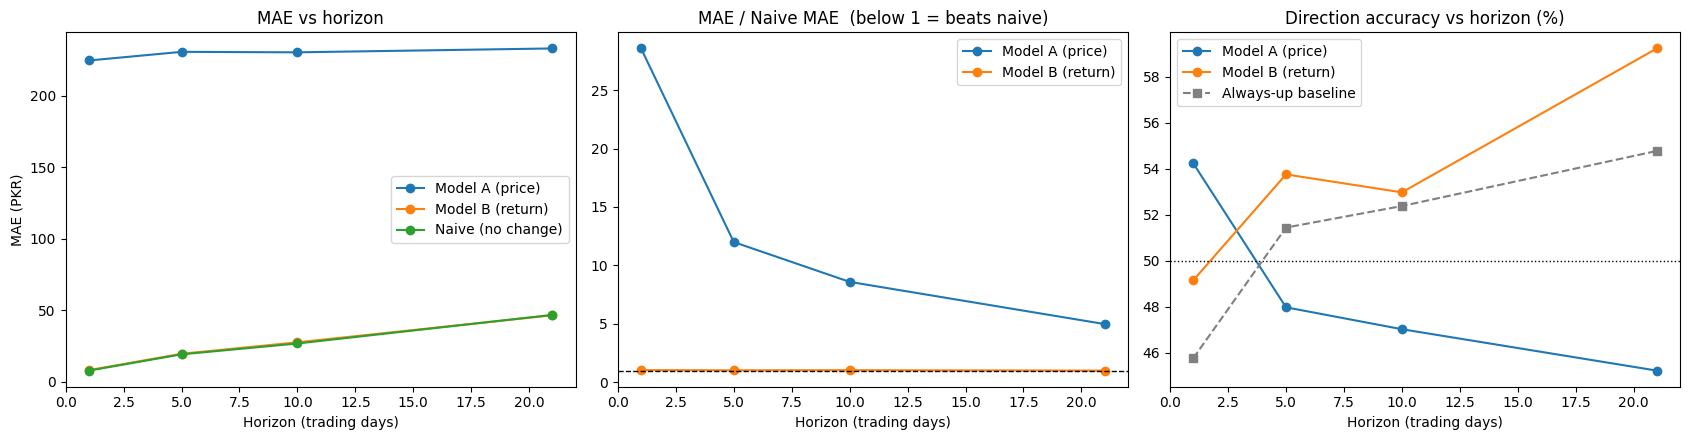

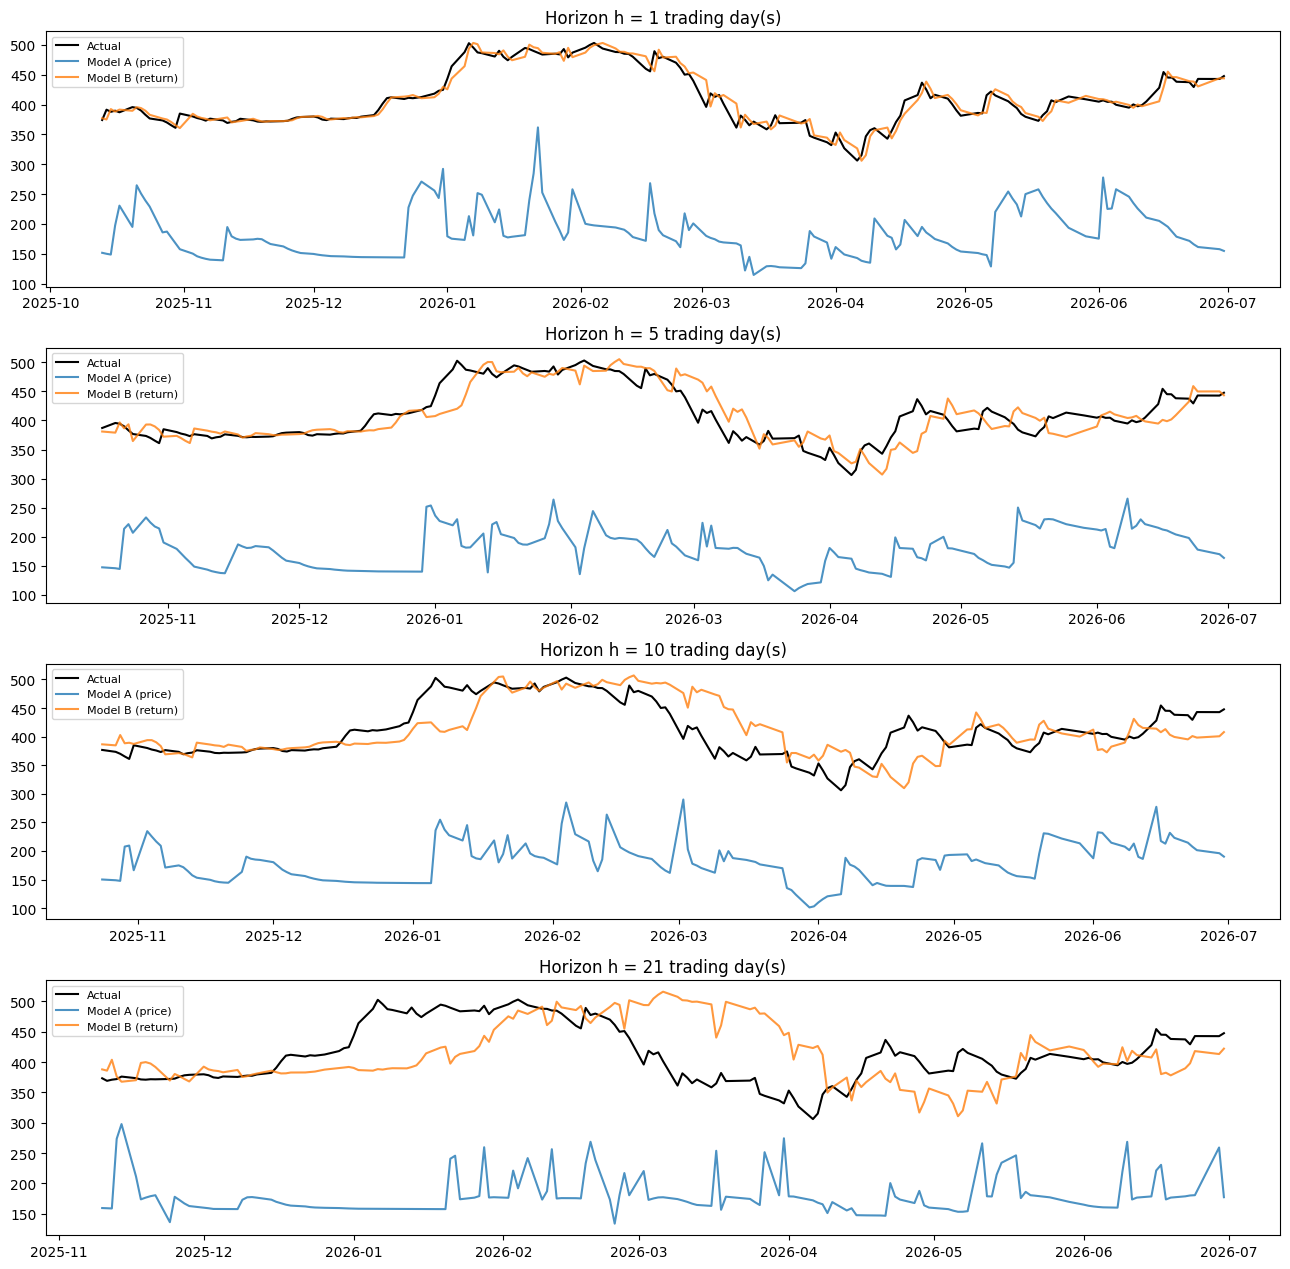

In [37]:
# ==========================================
# MH-5. PLOTS
# ==========================================
tbl = mh_table.reset_index()
models = ["Model A (price)", "Model B (return)", "Naive (no change)"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for m_ in models:
    t_ = tbl[tbl.model == m_]
    axes[0].plot(t_.horizon, t_.MAE, marker="o", label=m_)
axes[0].set_title("MAE vs horizon"); axes[0].set_xlabel("Horizon (trading days)"); axes[0].set_ylabel("MAE (PKR)")
axes[0].legend()

for m_ in models[:2]:
    t_ = tbl[tbl.model == m_]
    axes[1].plot(t_.horizon, t_.MAE_vs_naive, marker="o", label=m_)
axes[1].axhline(1.0, color="black", ls="--", lw=1)
axes[1].set_title("MAE / Naive MAE  (below 1 = beats naive)")
axes[1].set_xlabel("Horizon (trading days)"); axes[1].legend()

for m_ in models[:2]:
    t_ = tbl[tbl.model == m_]
    axes[2].plot(t_.horizon, t_.DirAcc, marker="o", label=m_)
axes[2].plot(up_rate_mh.index, up_rate_mh.values, marker="s", ls="--", color="grey", label="Always-up baseline")
axes[2].axhline(50, color="black", ls=":", lw=1)
axes[2].set_title("Direction accuracy vs horizon (%)")
axes[2].set_xlabel("Horizon (trading days)"); axes[2].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(13, 3.2 * len(HORIZONS)), sharex=False)
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    g_ = mh_pred[mh_pred.h == h]
    x_ = pd.to_datetime(g_.DATE)
    ax.plot(x_, g_.actual, color="black", lw=1.5, label="Actual")
    ax.plot(x_, g_.pred_A, alpha=.8, label="Model A (price)")
    ax.plot(x_, g_.pred_B, alpha=.8, label="Model B (return)")
    ax.set_title(f"Horizon h = {h} trading day(s)")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()